# 02 · Energy smearing and calibration of the photostatistics model

The simulation does not generate optical photons: the energy deposited in each bar is taken directly from the Geant4 volume and then smeared with a Gaussian that emulates the fluctuations of the SiPM readout. The parameter (relative FWHM) had been tuned to **0.22** so that the simulated offset distributions matched those of the 2018 test beam.

For the bar-size scan this model (`CONSTANT`, fixed σ_E/E) is not enough: thinner bars deposit less energy, collect fewer photoelectrons and have a worse relative resolution. The `PHOTOSTAT` model assumes σ_E/E ∝ 1/√E:

* `CONSTANT`: σ_E = s · E / 2.355
* `PHOTOSTAT`: σ_E = s · √(E · E_ref) / 2.355, with E_ref = 7 MeV (≈ mean energy per hit bar in the test beam)

The `PHOTOSTAT` parameter s is calibrated by requiring that, in the test-beam setup, it gives the **same offset distributions** as `CONSTANT` 0.22 (i.e. the same as the data).

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sithplot as sp
sp.setup()
import sith_reco as sr
R = sp.RUNS
geom = sr.Geometry()
pat = lambda d: str(R / d / "output" / "*MeV_t*-{run}.root")
calib = json.load(open(R / "scan_bars" / "calib" / "calibration.json"))
S_PHOT, E_REF = calib["photostat_smear"], 7.0
print(f"calibrated PHOTOSTAT: s = {S_PHOT:.4f} (E_ref = {E_REF} MeV)")

calibrated PHOTOSTAT: s = 0.1799 (E_ref = 7.0 MeV)


## 1. How much energy a bar sees

Geant4 deposits *without* smearing (run `const_0.0`) in the four bars of the pair used for the offset, over all test-beam steps. The sum over the two bars of a pair is roughly constant (≈ height × dE/dx); a single deposit ranges from almost zero (track near the apex) to the maximum.

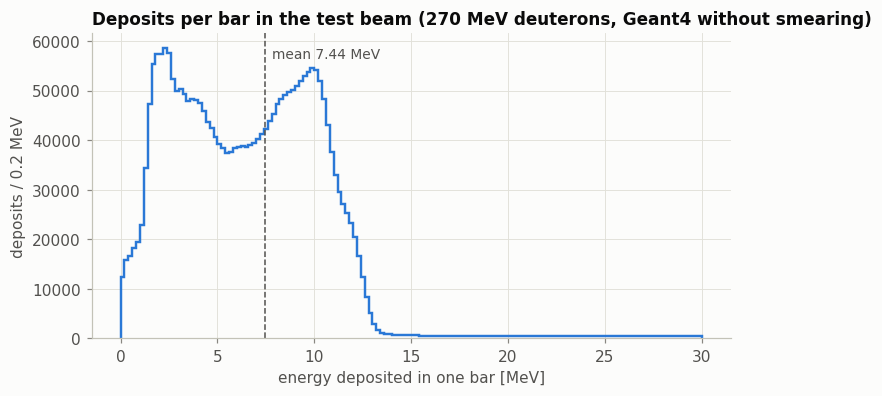

In [2]:
E = []
for k in range(7):
    F, B, _ = sr.load(sr.run_files(pat("const_0.0"), k), geom, extra=())
    for a in (F[:, 3], F[:, 11], B[:, 3], B[:, 11]):
        E.append(a[np.isfinite(a)])
E = np.concatenate(E)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
sp.hist_line(ax, E, 150, (0, 30), sp.SERIES[0])
ax.axvline(E.mean(), color=sp.INK2, lw=1, ls="--")
ax.annotate(f"mean {E.mean():.2f} MeV", (E.mean(), ax.get_ylim()[1] * 0.92), xytext=(5, 0),
            textcoords="offset points", color=sp.INK2, fontsize=9)
ax.set(xlabel="energy deposited in one bar [MeV]", ylabel="deposits / 0.2 MeV",
       title="Deposits per bar in the test beam (270 MeV deuterons, Geant4 without smearing)")
plt.show()

## 2. The two models compared

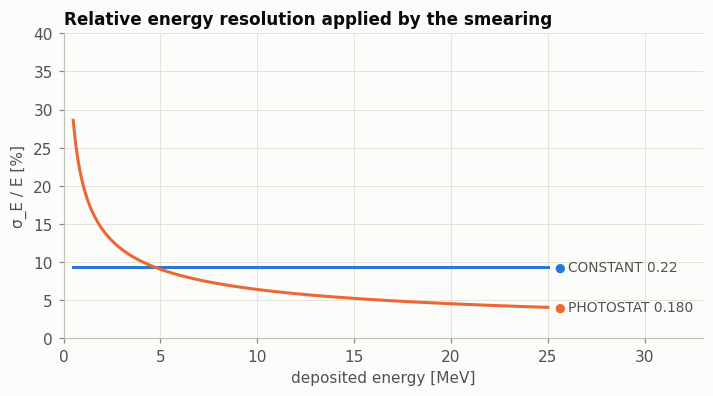

In [3]:
e = np.linspace(0.5, 25, 300)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(e, np.full_like(e, 100 * 0.22 / 2.355), color=sp.SERIES[0])
ax.plot(e, 100 * S_PHOT / 2.355 * np.sqrt(E_REF / e), color=sp.SERIES[1])
sp.end_label(ax, 25, 100 * 0.22 / 2.355, "CONSTANT 0.22", sp.SERIES[0])
sp.end_label(ax, 25, 100 * S_PHOT / 2.355 * np.sqrt(E_REF / 25), f"PHOTOSTAT {S_PHOT:.3f}", sp.SERIES[1])
ax.set(xlim=(0, 33), ylim=(0, 40), xlabel="deposited energy [MeV]", ylabel="σ_E / E [%]",
       title="Relative energy resolution applied by the smearing")
plt.show()

## 3. Test-beam resolution as a function of the smearing

Each point is a complete test-beam scan (7 steps × 100k events, same seeds), analysed as in the paper. Smearing 0 gives the physics-only contribution (Landau fluctuations, δ rays, multiple scattering, reconstruction non-linearity).

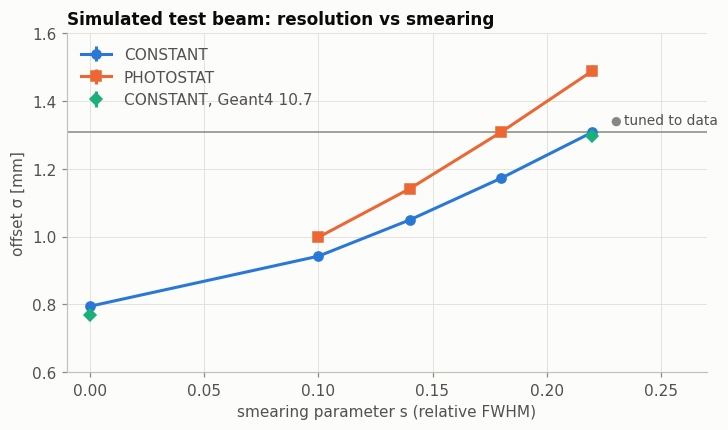

,model,smearing,offset σ [mm],error [mm]
0,CONSTANT,0.00,0.794670,0.002291
1,CONSTANT,0.10,0.942387,0.002964
2,CONSTANT,0.14,1.049422,0.003797
3,CONSTANT,0.18,1.172484,0.005340
4,CONSTANT,0.22,1.308431,0.008261
5,PHOTOSTAT,0.10,0.998155,0.003333
6,PHOTOSTAT,0.14,1.141480,0.004826
7,PHOTOSTAT,0.18,1.308470,0.008143
8,PHOTOSTAT,0.22,1.489447,0.015853
9,"CONSTANT, Geant4 10.7",0.00,0.767902,0.002203


In [4]:
def tb(d):
    r = sr.analyse_tb(pat(d), 7, geom)
    return r["sigma_mm_mean"], r["sigma_mm_err_mean"]

rows = []
for s in ("0.0", "0.10", "0.14", "0.18", "0.22"):
    rows.append(("CONSTANT", float(s), *tb(f"const_{s}")))
for s in ("0.10", "0.14", "0.18", "0.22"):
    rows.append(("PHOTOSTAT", float(s), *tb(f"phot_{s}")))
for s in ("0.0", "0.22"):
    rows.append(("CONSTANT, Geant4 10.7", float(s), *tb(f"g4107_{s}")))
scan = pd.DataFrame(rows, columns=["model", "smearing", "offset σ [mm]", "error [mm]"])
target = scan.query("model == 'CONSTANT' and smearing == 0.22")["offset σ [mm]"].item()

fig, ax = plt.subplots(figsize=(7.5, 4))
styles = {"CONSTANT": (sp.SERIES[0], "o-"), "PHOTOSTAT": (sp.SERIES[1], "s-"), "CONSTANT, Geant4 10.7": (sp.SERIES[2], "D")}
for m, g in scan.groupby("model", sort=False):
    c, f = styles[m]
    ax.errorbar(g.smearing, g["offset σ [mm]"], g["error [mm]"], fmt=f, color=c, label=m, ms=6)
ax.axhline(target, color=sp.MUTED, lw=1)
sp.end_label(ax, 0.225, target, "tuned to data", sp.MUTED, dy=8)
ax.set(xlim=(-0.01, 0.27), ylim=(0.6, 1.6), xlabel="smearing parameter s (relative FWHM)",
       ylabel="offset σ [mm]", title="Simulated test beam: resolution vs smearing")
ax.legend(loc="upper left")
plt.show()
scan

## 4. Calibration of `PHOTOSTAT`

Dedicated runs of 7 × 200k events with **the same seeds** for every value of s and for the `CONSTANT` 0.22 reference: the Geant4 part of the events is identical, only the smearing changes, so the differences between points have little noise.

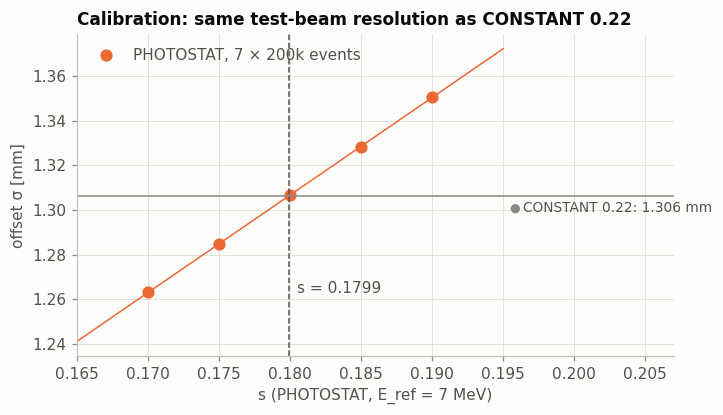

In [5]:
s = np.array(calib["smear"]); y = np.array(calib["sigma_mm"])
xx = np.linspace(s.min() - 0.005, s.max() + 0.005, 50)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(s, y, "o", color=sp.SERIES[1], ms=7, label="PHOTOSTAT, 7 × 200k events")
ax.plot(xx, calib["slope"] * xx + calib["intercept"], color=sp.SERIES[1], lw=1)
ax.axhline(calib["target_mm"], color=sp.MUTED, lw=1)
ax.axvline(S_PHOT, color=sp.INK2, lw=1, ls="--")
sp.end_label(ax, xx[-1], calib["target_mm"], f"CONSTANT 0.22: {calib['target_mm']:.3f} mm", sp.MUTED, dy=-8)
ax.annotate(f"s = {S_PHOT:.4f}", (S_PHOT, y.min()), xytext=(5, 0), textcoords="offset points", color=sp.INK2)
ax.set(xlim=(xx[0], xx[-1] + 0.012), xlabel="s (PHOTOSTAT, E_ref = 7 MeV)", ylabel="offset σ [mm]",
       title="Calibration: same test-beam resolution as CONSTANT 0.22")
ax.legend(loc="upper left")
plt.show()

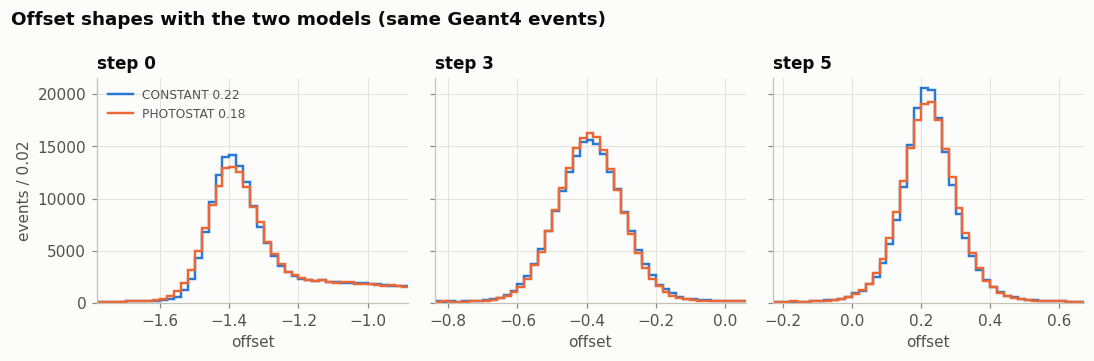

In [6]:
# shape comparison: CONSTANT 0.22 vs the grid PHOTOSTAT value closest to the calibration
near = min(calib["smear"], key=lambda v: abs(v - S_PHOT))
def offs(d):
    out = []
    for k in range(7):
        F, B, _ = sr.load(sr.run_files(str(R / "scan_bars" / "calib" / d / "output" / "*MeV_t*-{run}.root"), k), geom, extra=())
        qF, rF, eF = sr.select_pairs(F, 7); qB, rB, eB = sr.select_pairs(B, 7)
        m = (qF == 3) & (rF == 11) & (qB >= 0)
        out.append(eF[m] - eB[m])
    return out
oc, op = offs("const_0.22"), offs(f"phot_{near}")
fig, axs = plt.subplots(1, 3, figsize=(10, 3.3), sharey=True)
for ax, k in zip(axs, (0, 3, 5)):
    sp.hist_line(ax, oc[k], 200, (-2, 2), sp.SERIES[0], label="CONSTANT 0.22")
    sp.hist_line(ax, op[k], 200, (-2, 2), sp.SERIES[1], label=f"PHOTOSTAT {near}")
    mu = np.median(oc[k]); ax.set(xlim=(mu - 0.45, mu + 0.45), title=f"step {k}", xlabel="offset")
axs[0].set_ylabel("events / 0.02"); axs[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Offset shapes with the two models (same Geant4 events)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Reading.**

* Without smearing Geant4 already gives ~0.8 mm (offset width): the 0.22 smearing brings it to ~1.31 mm and reproduces the data.
* `PHOTOSTAT` with s ≈ 0.18 (E_ref = 7 MeV) gives the same width and very similar shapes: above E_ref the resolution is slightly better than `CONSTANT`, below it is worse (tails from the small deposits near the apexes).
* In the bar scan the calibrated model is what matters: with thin bars the energy drops and the relative resolution degrades as 1/√E, which `CONSTANT` ignores.

*Known limitation:* the model assumes the same photoelectron yield per MeV for every geometry. In reality bars with a smaller cross-section have a larger fraction of their end face covered by the SiPM (6×6 mm²) and collect more light per MeV: this effect, favourable to small bars, is not included.